In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

from sklearn.datasets import (
    load_wine,
    load_digits,
    fetch_california_housing
)

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error
from sklearn.datasets import load_sample_image

In [50]:
rng = np.random.default_rng(42)

along = np.array([1.0, 0.55])
along = along / np.linalg.norm(along)
across = np.array([-along[1], along[0]])

def stretched_group(center, n):
    return center + np.outer(rng.normal(0, 0.95, n), along) + np.outer(rng.normal(0, 0.28, n), across)

normal = np.vstack([
    stretched_group(-4 * along, 170),
    stretched_group(4 * along, 170)
])

planted = np.array([
    [-1.5, 2.6], [2.2, -2.4], [-4.8, 1.2],
    [5.0, -0.4], [0, 0], [8.6, 4.8]
])

X_anom = np.vstack([normal, planted])
is_planted = np.r_[np.zeros(340, bool), np.ones(6, bool)]

In [51]:
def flag_top(scores, rate=0.05):
    return scores > np.percentile(scores, 100 * (1 - rate))

km = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_anom)
k_flags = flag_top(km.transform(X_anom).min(axis=1))

d_flags = DBSCAN(eps=0.7, min_samples=6).fit(X_anom).labels_ == -1

gmm = GaussianMixture(n_components=2, random_state=42).fit(X_anom)
g_flags = flag_top(-gmm.score_samples(X_anom))

pca = PCA(n_components=1).fit(X_anom)
back = pca.inverse_transform(pca.transform(X_anom))
p_flags = flag_top(((X_anom - back) ** 2).sum(axis=1))

for name, flags in {
    "K-Means": k_flags,
    "DBSCAN": d_flags,
    "GMM": g_flags,
    "PCA": p_flags
}.items():
    print(name, flags[~is_planted].sum())

K-Means 12
DBSCAN 2
GMM 12
PCA 14


In [52]:
iso = IsolationForest(random_state=42)
iso.fit(X_anom)

scores = -iso.score_samples(X_anom)

flags = scores > np.percentile(scores, 98)

print(planted[flags[is_planted]])

[[-1.5  2.6]
 [ 2.2 -2.4]
 [-4.8  1.2]
 [ 5.  -0.4]
 [ 0.   0. ]
 [ 8.6  4.8]]


In [53]:
for i in range(len(planted)):
    print(i, planted[i], flags[340 + i])

0 [-1.5  2.6] True
1 [ 2.2 -2.4] True
2 [-4.8  1.2] True
3 [ 5.  -0.4] True
4 [0. 0.] True
5 [8.6 4.8] True


In [54]:
wine = load_wine(as_frame=True)

X = StandardScaler().fit_transform(wine.data)

pca = PCA(n_components=2)
back = pca.inverse_transform(pca.fit_transform(X))

scores = ((X - back) ** 2).mean(axis=1)

flagged = np.where(scores > np.percentile(scores, 98))[0]

print(flagged)

[ 59  69  95 121]


In [55]:
pca8 = PCA(n_components=8)
back8 = pca8.inverse_transform(pca8.fit_transform(X))

scores8 = ((X - back8) ** 2).mean(axis=1)

flagged8 = np.where(scores8 > np.percentile(scores8, 98))[0]

print("2 components:", flagged)
print("8 components:", flagged8)
print("Same wines:", np.array_equal(flagged, flagged8))

2 components: [ 59  69  95 121]
8 components: [ 73  84 105 121]
Same wines: False


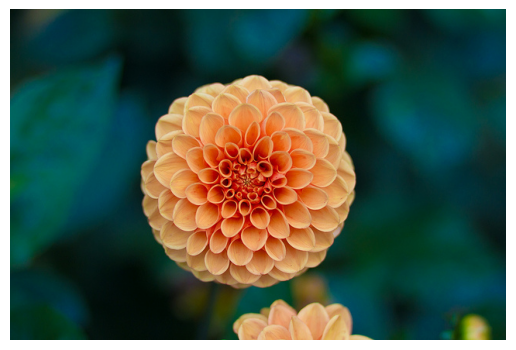

In [56]:
img= load_sample_image("flower.jpg")

pixels = img.reshape(-1, 3)

plt.imshow(img)
plt.axis("off")
plt.show()

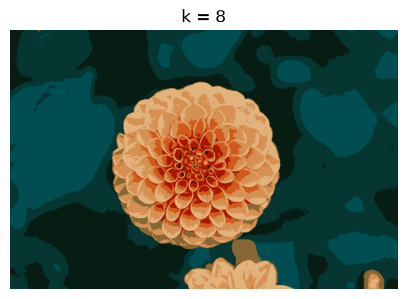

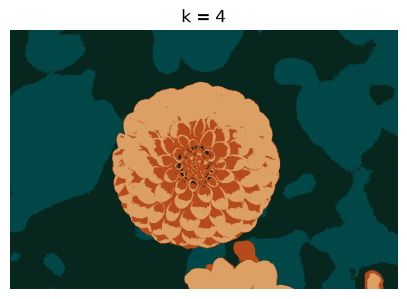

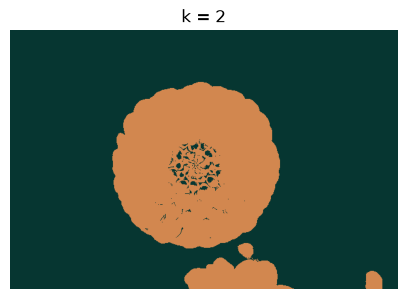

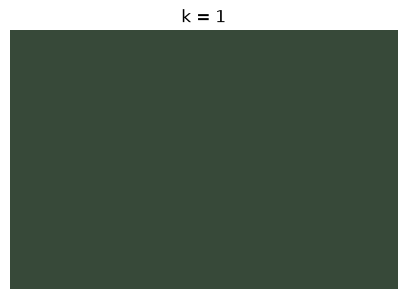

In [57]:
x = img.reshape(-1, 3)

for k in [8, 4, 2, 1]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(x)

    new_img = km.cluster_centers_[labels]
    new_img = new_img.reshape(img.shape)

    plt.figure(figsize=(5, 5))
    plt.imshow(new_img.astype(int))
    plt.title(f"k = {k}")
    plt.axis("off")
    plt.show()

In [58]:


X, y = load_digits(return_X_y=True)

X_train, y_train = X[:1400], y[:1400]
X_test, y_test = X[1400:], y[1400:]

for n in [20, 100]:
    model = KMeans(n_clusters=n, random_state=42, n_init=10)
    distances = model.fit_transform(X_train)

    idx = distances.argmin(axis=0)

    print("Labels:", n)
    print("First images:", LogisticRegression(max_iter=10000).fit(
        X_train[:n], y_train[:n]).score(X_test, y_test))

    print("Representative images:", LogisticRegression(max_iter=10000).fit(
        X_train[idx], y_train[idx]).score(X_test, y_test))

Labels: 20
First images: 0.707808564231738
Representative images: 0.8312342569269522
Labels: 100
First images: 0.8085642317380353
Representative images: 0.889168765743073


In [59]:


X, y = load_digits(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [60]:
for n in [0.80, 0.99]:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=n)),
        ("clf", LogisticRegression(max_iter=5000))
    ])

    model.fit(X_train, y_train)

    print("PCA:", n)
    print("Features:", model.named_steps["pca"].n_components_)
    print("Accuracy:", model.score(X_test, y_test))

PCA: 0.8
Features: 21
Accuracy: 0.9388888888888889
PCA: 0.99
Features: 54
Accuracy: 0.975


In [61]:
housing = fetch_california_housing(as_frame=True)

X_train, X_test, y_train, y_test = train_test_split(
    housing.data, housing.target,
    test_size=0.2, random_state=42
)

geo = ColumnTransformer([
    ("geo", KMeans(n_clusters=20, random_state=42),
     ["Latitude", "Longitude"])
], remainder="passthrough")

model = Pipeline([
    ("features", geo),
    ("scale", StandardScaler()),
    ("reg", LinearRegression())
])

In [62]:
search = GridSearchCV(
    model,
    {"features__geo__n_clusters": [100, 150, 200]},
    cv=3,
    scoring="neg_root_mean_squared_error"
)

search.fit(X_train, y_train)

for k, score in zip(
    search.cv_results_["param_features__geo__n_clusters"],
    search.cv_results_["mean_test_score"]
):
    print(k, round(-score, 3))

print("Best clusters:", search.best_params_)
print("Best RMSE:", -search.best_score_)

100 0.591
150 0.569
200 0.555
Best clusters: {'features__geo__n_clusters': 200}
Best RMSE: 0.5545619981076421
